In [1]:
pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load dataset
df = pd.read_csv("/kaggle/input/datasets/atharvahjoshi/uber-dataset/uber.xls")

In [3]:

# Display first 5 rows
df.head()

df.tail(10)


# Display all column names
print(df.columns)

# Dataset rows and columns
print(df.shape)

# Dataset information
print(df.info())

# Statistical summary
print(df.describe())

# Check missing values
print(df.isnull().sum())

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')
(200000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None
         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \


                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000125         0.002826   
pickup_longitude      0.000125          1.000000        -0.811435   
pickup_latitude       0.002826         -0.811435         1.000000   
dropoff_longitude    -0.002534          0.835878        -0.766797   
dropoff_latitude      0.000715         -0.850520         0.683972   
passenger_count       0.011995         -0.000582        -0.001742   

                   dropoff_longitude  dropoff_latitude  passenger_count  
fare_amount                -0.002534          0.000715         0.011995  
pickup_longitude            0.835878         -0.850520        -0.000582  
pickup_latitude            -0.766797          0.683972        -0.001742  
dropoff_longitude           1.000000         -0.913666         0.000271  
dropoff_latitude           -0.913666          1.000000        -0.000911  
passenger_count             0.000271         -0.000911         1.000000 

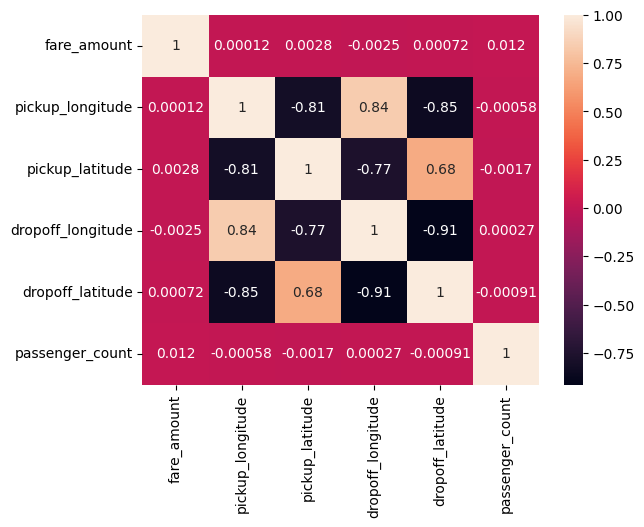

Linear Regression
R2 Score: 0.0001352830566775376
RMSE: 4.129226610295564
MAE: 3.2826102241436774
Random Forest Regression
R2 Score: 0.7047322878232607
RMSE: 2.243913313302495
MAE: 1.5690622742015814


In [4]:



# 2. Preprocessing
df = df.dropna()
df = df.drop_duplicates()

# Remove unnecessary columns
df = df.drop(['Unnamed: 0', 'key'], axis=1, errors='ignore')

# Remove invalid fare values
df = df[df['fare_amount'] > 0]

# Remove invalid passenger count
df = df[df['passenger_count'] > 0]

# 3. Identify outliers using IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df['fare_amount'] >= lower) &
        (df['fare_amount'] <= upper)]

# 4. Correlation
print(df.corr(numeric_only=True))

sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

# 5. Select features and target
X = df[['pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude',
        'passenger_count']]

y = df['fare_amount']

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred1 = lr.predict(X_test)

print("Linear Regression")
print("R2 Score:", r2_score(y_test, y_pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred1)))
print("MAE:", mean_absolute_error(y_test, y_pred1))

# 8. Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred2 = rf.predict(X_test)

print("Random Forest Regression")
print("R2 Score:", r2_score(y_test, y_pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred2)))
print("MAE:", mean_absolute_error(y_test, y_pred2))


In [5]:
# Input: pickup_longitude, pickup_latitude,
#        dropoff_longitude, dropoff_latitude, passenger_count

arr = [[-73.98, 40.75, -73.97, 40.76, 2]]

# Linear Regression prediction
print("Linear Regression Fare:", lr.predict(arr)[0])

# Random Forest prediction
print("Random Forest Fare:", rf.predict(arr)[0])

Linear Regression Fare: 8.960139972697892
Random Forest Fare: 6.693999999999999


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
